In [ ]:
import tensorflow as tf
from tensorflow.keras import mixed_precision

# Enable Mixed Precision globally
mixed_precision.set_global_policy('mixed_float16')

print("✅ Mixed precision policy enabled:", mixed_precision.global_policy())

✅ Mixed precision policy enabled: <DTypePolicy "mixed_float16">


In [ ]:
"""
NCT-CRC JPEG2000 Compression Experiments
==========================================
Replicates BreakHis/BACH pipeline for NCT-CRC-HE-100K (36,579 image subset).
Binary classification: benign vs malignant colorectal tissue.

Experiments:
  1. Adaptation: train & test at matched CR levels
  2. Robustness: train on CR1, test on all CRs
  3. CAT: train on mixed CR1+CR15+CR25+CR50+CR100, test on all CRs

Run on Colab with GPU (L4 recommended). Estimated time: 8-12 hours total.
"""

# ============================================================
# CELL 1: Install dependencies
# ============================================================
!pip install codecarbon --quiet

# ============================================================
# CELL 2: Imports
# ============================================================

import os
import glob
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import InceptionV3, DenseNet169
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                              precision_score, recall_score, f1_score,
                              matthews_corrcoef, roc_auc_score,
                              confusion_matrix, cohen_kappa_score)
from codecarbon import EmissionsTracker
import warnings
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

print(f"TensorFlow: {tf.__version__}")
print(f"GPU: {tf.config.list_physical_devices('GPU')}")

# ============================================================
# CELL 3: Configuration
# ============================================================

BASE_DIR = '/content/drive/MyDrive/NCT_CRC_PLOS_ONE/NCT_CRC_Split'
OUTPUT_DIR = '/content/drive/MyDrive/NCT_CRC_PLOS_ONE/NCT_CRC_Results_Final'
METADATA_CSV = '/content/drive/MyDrive/NCT_CRC_PLOS_ONE/nct_crc_metadata.csv'

CR_LEVELS = ['CR1_original', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000']
CR_LABELS = ['CR1', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000']
CAT_LEVELS = ['CR1_original', 'CR15', 'CR25', 'CR50', 'CR100']  # For Exp 3

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
MAX_EPOCHS = 30
N_FOLDS = 5
RANDOM_SEED = 42
LEARNING_RATE = 0.001

# Create output directories
for subdir in ['results', 'models', 'figures', 'emissions']:
    os.makedirs(os.path.join(OUTPUT_DIR, subdir), exist_ok=True)

# ============================================================
# CELL 4 (FIXED v3): Proper balanced split for NCT-CRC
# ============================================================
# The original split had 0 benign images in train.
# This version pools ALL images and creates a fresh
# 70/15/15 stratified split with both classes in all sets.

import os
import glob
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

BASE_DIR = '/content/drive/MyDrive/NCT_CRC_PLOS_ONE/NCT_CRC_Split'
SAMPLE_SIZE = 7800
RANDOM_SEED = 42

CR_LEVELS = ['CR1_original', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000']
CR_LABELS = ['CR1', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000']
CAT_LEVELS = ['CR1_original', 'CR15', 'CR25', 'CR50', 'CR100']

# ── Step 1: Pool ALL images ignoring original splits ──
print("🔍 Pooling all CR1_original images (ignoring original train/val/test)...")

records = []
cr1_path = os.path.join(BASE_DIR, 'CR1_original')

for split in ['train', 'test', 'val']:
    for cls in ['benign', 'malignant']:
        pattern = os.path.join(cr1_path, split, cls, '*.png')
        files = glob.glob(pattern)
        label = 0 if cls == 'benign' else 1
        for fpath in files:
            records.append({
                'filename': os.path.basename(fpath),
                'original_split': split,
                'original_class_folder': cls,
                'label': label,
            })
        if files:
            print(f"  {split}/{cls}: {len(files)} images")

all_images = pd.DataFrame(records)
print(f"\n  Total pooled: {len(all_images)} images")
print(f"  Benign: {(all_images['label']==0).sum()} | Malignant: {(all_images['label']==1).sum()}")

# ── Step 2: Stratified sample ──
np.random.seed(RANDOM_SEED)
sampled = all_images.groupby('label', group_keys=False).apply(
    lambda x: x.sample(
        n=min(len(x), int(SAMPLE_SIZE * len(x) / len(all_images))),
        random_state=RANDOM_SEED
    )
).reset_index(drop=True)

print(f"\n📊 Sampled {len(sampled)} images:")
print(f"  Benign: {(sampled['label']==0).sum()} | Malignant: {(sampled['label']==1).sum()}")

# ── Step 3: Create FRESH 70/15/15 stratified split ──
# First split: 70% train+val, 30% test
train_val_df, test_df = train_test_split(
    sampled, test_size=0.15, random_state=RANDOM_SEED,
    stratify=sampled['label']
)

# Second split: from the 85%, split 15/85 ≈ 17.6% for val
train_df, val_df = train_test_split(
    train_val_df, test_size=0.176, random_state=RANDOM_SEED,
    stratify=train_val_df['label']
)

# Assign new split labels
train_df = train_df.copy(); train_df['split'] = 'train'
val_df = val_df.copy(); val_df['split'] = 'val'
test_df = test_df.copy(); test_df['split'] = 'test'

sampled = pd.concat([train_df, val_df, test_df], ignore_index=True)

print(f"\n✅ FRESH BALANCED SPLIT:")
for sp in ['train', 'val', 'test']:
    sp_data = sampled[sampled['split'] == sp]
    n_ben = (sp_data['label'] == 0).sum()
    n_mal = (sp_data['label'] == 1).sum()
    pct_ben = n_ben / len(sp_data) * 100
    print(f"  {sp:>5s}: {len(sp_data):>5d} images | "
          f"Benign: {n_ben:>4d} ({pct_ben:.1f}%) | "
          f"Malignant: {n_mal:>4d} ({100-pct_ben:.1f}%)")

# Save split indices for reproducibility
split_csv_path = os.path.join(
    '/content/drive/MyDrive/NCT_CRC_PLOS_ONE/NCT_CRC_Results_Final',
    'nct_crc_subset_splits.csv'
)
os.makedirs(os.path.dirname(split_csv_path), exist_ok=True)
sampled[['filename', 'label', 'split', 'original_split', 'original_class_folder']].to_csv(
    split_csv_path, index=False
)
print(f"\n📄 Split indices saved: {split_csv_path}")

# ── Step 4: Build path remapping ──
def get_filepath(row, cr_level):
    """Map a sampled image to its path in any CR folder."""
    return os.path.join(BASE_DIR, cr_level,
                         row['original_split'],
                         row['original_class_folder'],
                         row['filename'])

def discover_images(base_dir, cr_level):
    """Build image DataFrame for a CR level using balanced splits."""
    rows = []
    for _, row in sampled.iterrows():
        fpath = get_filepath(row, cr_level)
        rows.append({
            'filepath': fpath,
            'filename': row['filename'],
            'split': row['split'],  # uses NEW split, not original
            'label': row['label'],
            'class_name': 'benign' if row['label'] == 0 else 'malignant',
            'cr_level': cr_level,
        })
    return pd.DataFrame(rows)

# ── Step 5: Verify ──
print(f"\n🔍 Verifying across CR levels...")
for cr_level, cr_label in zip(CR_LEVELS, CR_LABELS):
    cr_data = discover_images(BASE_DIR, cr_level)
    train_val = cr_data[cr_data['split'].isin(['train', 'val'])]

    check_paths = cr_data['filepath'].sample(min(20, len(cr_data)), random_state=42).values
    exists = sum(1 for p in check_paths if os.path.exists(p))
    status = '✅' if exists == len(check_paths) else f'⚠️ {exists}/{len(check_paths)}'

    n_ben_tv = (train_val['label'] == 0).sum()
    n_mal_tv = (train_val['label'] == 1).sum()

    print(f"  {cr_label:>8s}: {len(cr_data)} imgs | "
          f"Train+Val: B:{n_ben_tv} M:{n_mal_tv} | "
          f"Test: {(cr_data['split']=='test').sum()} | {status}")

print(f"\n✅ Ready. Balanced splits with both classes in train/val/test.")
print(f"   This resolves the reviewer's critical concern (§1.1).")

# ============================================================
# CELL 5: Model Architecture (Inception-DenseNet169-Attention)
# ============================================================

def build_inception_densenet_attention(input_shape=(224, 224, 3)):
    """Build the Inception-DenseNet169-Attention Hybrid model."""

    inputs = layers.Input(shape=input_shape)

    # Data augmentation
    x = layers.RandomRotation(0.15)(inputs)
    x = layers.RandomFlip('horizontal')(x)
    x = layers.RandomFlip('vertical')(x)
    x = layers.RandomZoom(0.15)(x)

    # Branch 1: InceptionV3
    inception_base = InceptionV3(weights='imagenet', include_top=False,
                                  input_shape=input_shape, pooling='avg')
    inception_base.trainable = False
    inception_out = inception_base(x)  # (batch, 2048)

    # Branch 2: DenseNet169
    densenet_base = DenseNet169(weights='imagenet', include_top=False,
                                 input_shape=input_shape, pooling='avg')
    densenet_base.trainable = False
    densenet_out = densenet_base(x)  # (batch, 1664)

    # Feature projection to common 512-dim space
    inc_proj = layers.Dense(512, activation='relu')(inception_out)
    inc_proj = layers.BatchNormalization()(inc_proj)

    dense_proj = layers.Dense(512, activation='relu')(densenet_out)
    dense_proj = layers.BatchNormalization()(dense_proj)

    # Reshape for attention: (batch, 1, 1, 512)
    inc_proj = layers.Reshape((1, 1, 512))(inc_proj)
    dense_proj = layers.Reshape((1, 1, 512))(dense_proj)

    # Concatenate: (batch, 1, 1, 1024)
    fused = layers.Concatenate(axis=-1)([inc_proj, dense_proj])

    # Channel Attention (CBAM-style)
    # Global Average Pooling path
    gap = layers.GlobalAveragePooling2D()(fused)  # (batch, 1024)
    gap_mlp = layers.Dense(256, activation='relu')(gap)
    gap_mlp = layers.Dense(1024)(gap_mlp)

    # Global Max Pooling path
    gmp = layers.GlobalMaxPooling2D()(fused)  # (batch, 1024)
    gmp_mlp = layers.Dense(256, activation='relu')(gmp)
    gmp_mlp = layers.Dense(1024)(gmp_mlp)

    # Combine and apply sigmoid
    attention = layers.Add()([gap_mlp, gmp_mlp])
    attention = layers.Activation('sigmoid')(attention)
    attention = layers.Reshape((1, 1, 1024))(attention)

    # Apply attention
    refined = layers.Multiply()([fused, attention])

    # Classification head
    flat = layers.Flatten()(refined)
    flat = layers.BatchNormalization()(flat)
    flat = layers.Dropout(0.5)(flat)
    fc = layers.Dense(256, activation='relu')(flat)
    fc = layers.Dropout(0.3)(fc)
    output = layers.Dense(1, activation='sigmoid')(fc)

    model = Model(inputs=inputs, outputs=output)
    return model


# Quick test
test_model = build_inception_densenet_attention()
print(f"✅ Model built: {test_model.count_params():,} parameters")
del test_model


# ============================================================
# CELL 6: Data Loading Utilities
# ============================================================

def load_dataset(filepaths, labels, batch_size=32, shuffle=True):
    """Create tf.data.Dataset from file paths and labels."""

    def load_and_preprocess(filepath, label):
        img = tf.io.read_file(filepath)
        img = tf.image.decode_png(img, channels=3)
        img = tf.image.resize(img, IMG_SIZE)
        img = tf.cast(img, tf.float32) / 255.0
        return img, label

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(filepaths), 10000), seed=RANDOM_SEED)
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


def get_class_weights(labels):
    """Compute inverse frequency class weights."""
    counts = np.bincount(labels.astype(int))
    total = len(labels)
    weights = {i: total / (len(counts) * c) for i, c in enumerate(counts)}
    return weights


# ============================================================
# CELL 7: Evaluation Function
# ============================================================

def evaluate_model(model, test_ds, test_labels):
    """Compute all classification metrics."""
    y_pred_prob = model.predict(test_ds, verbose=0).flatten()
    y_pred = (y_pred_prob >= 0.5).astype(int)
    y_true = test_labels.astype(int)

    # Handle edge cases
    try:
        auc = roc_auc_score(y_true, y_pred_prob)
    except ValueError:
        auc = 0.5

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'specificity': specificity,
        'f1_score': f1_score(y_true, y_pred, zero_division=0),
        'mcc': matthews_corrcoef(y_true, y_pred),
        'auc_roc': auc,
    }


# ============================================================
# CELL 8: Training Function
# ============================================================

def train_and_evaluate(train_paths, train_labels, val_paths, val_labels,
                        test_paths, test_labels, class_weights,
                        model_save_path=None, tracker=None):
    """Train model and return metrics."""

    # Build fresh model
    model = build_inception_densenet_attention()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    # Create datasets
    train_ds = load_dataset(train_paths, train_labels, BATCH_SIZE, shuffle=True)
    val_ds = load_dataset(val_paths, val_labels, BATCH_SIZE, shuffle=False)
    test_ds = load_dataset(test_paths, test_labels, BATCH_SIZE, shuffle=False)

    # Callbacks
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7),
    ]

    # Train
    t0 = time.time()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=MAX_EPOCHS,
        callbacks=callbacks,
        class_weight=class_weights,
        verbose=0,
    )
    train_time = time.time() - t0

    # Evaluate
    metrics = evaluate_model(model, test_ds, test_labels)
    metrics['training_time_sec'] = train_time
    metrics['epochs_trained'] = len(history.history['loss'])

    # Save model
    if model_save_path:
        model.save(model_save_path)

    # Clean up
    keras.backend.clear_session()
    del model
    tf.keras.backend.clear_session()

    return metrics


# ============================================================
# CELL 9: Cross-Validation Runner
# ============================================================

def run_cv_experiment(data_df, test_df, experiment_name, cr_label,
                       model_prefix, tracker=None):
    """Run 5-fold stratified CV and return results."""

    train_val_paths = data_df['filepath'].values
    train_val_labels = data_df['label'].values
    test_paths = test_df['filepath'].values
    test_labels = test_df['label'].values

    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    fold_results = []

    for fold, (train_idx, val_idx) in enumerate(skf.split(train_val_paths, train_val_labels)):
        fold_num = fold + 1
        print(f"    Fold {fold_num}/{N_FOLDS}...", end=' ', flush=True)

        tr_paths = train_val_paths[train_idx]
        tr_labels = train_val_labels[train_idx]
        vl_paths = train_val_paths[val_idx]
        vl_labels = train_val_labels[val_idx]

        class_weights = get_class_weights(tr_labels)

        save_path = os.path.join(OUTPUT_DIR, 'models',
                                  f'{model_prefix}_{cr_label}_fold{fold_num}.keras')

        metrics = train_and_evaluate(
            tr_paths, tr_labels, vl_paths, vl_labels,
            test_paths, test_labels, class_weights,
            model_save_path=save_path, tracker=tracker
        )

        metrics['fold'] = fold_num
        metrics['cr_level'] = cr_label
        metrics['experiment'] = experiment_name
        fold_results.append(metrics)

        print(f"Acc={metrics['accuracy']:.4f} F1={metrics['f1_score']:.4f} "
              f"({metrics['epochs_trained']} epochs, {metrics['training_time_sec']:.0f}s)")

    return fold_results


# ============================================================
# CELL 10: EXPERIMENT 1 — ADAPTATION (with per-CR emissions)
# ============================================================

print("=" * 60)
print("  EXPERIMENT 1: ADAPTATION STUDY")
print("  Train and test at matched compression levels")
print("=" * 60)

exp1_results = []
exp1_emissions = []

for i, (cr_level, cr_label) in enumerate(zip(CR_LEVELS, CR_LABELS)):
    print(f"\n  [{i+1}/{len(CR_LEVELS)}] {cr_label}")

    cr_data = discover_images(BASE_DIR, cr_level)
    if cr_data.empty:
        print(f"    ⚠️ No images found, skipping")
        continue

    train_val = cr_data[cr_data['split'].isin(['train', 'val'])]
    test = cr_data[cr_data['split'] == 'test']

    n_ben = (train_val['label']==0).sum()
    n_mal = (train_val['label']==1).sum()
    print(f"    Train+Val: {len(train_val)} | Test: {len(test)} | B:{n_ben} M:{n_mal}")

    for fold_num in range(1, N_FOLDS + 1):
        # Track emissions per CR × fold
        tracker = EmissionsTracker(
            project_name=f"exp1_{cr_label}_fold{fold_num}",
            output_dir=os.path.join(OUTPUT_DIR, 'emissions'),
            log_level="error"
        )
        tracker.start()

        # Run fold manually (same as run_cv_experiment but with emission tracking)
        skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
        train_val_paths = train_val['filepath'].values
        train_val_labels = train_val['label'].values

        splits = list(skf.split(train_val_paths, train_val_labels))
        train_idx, val_idx = splits[fold_num - 1]

        tr_paths = train_val_paths[train_idx]
        tr_labels = train_val_labels[train_idx]
        vl_paths = train_val_paths[val_idx]
        vl_labels = train_val_labels[val_idx]

        test_paths = test['filepath'].values
        test_labels = test['label'].values

        class_weights = get_class_weights(tr_labels)
        save_path = os.path.join(OUTPUT_DIR, 'models',
                                  f'exp1_adaptation_{cr_label}_fold{fold_num}.keras')

        print(f"    Fold {fold_num}/{N_FOLDS}...", end=' ', flush=True)

        metrics = train_and_evaluate(
            tr_paths, tr_labels, vl_paths, vl_labels,
            test_paths, test_labels, class_weights,
            model_save_path=save_path
        )

        emissions_data = tracker.stop()

        metrics['fold'] = fold_num
        metrics['cr_level'] = cr_label
        metrics['experiment'] = 'exp1_adaptation'
        exp1_results.append(metrics)

        # Record emissions
        co2_g = emissions_data * 1000 if emissions_data else 0  # kg to g
        exp1_emissions.append({
            'task': f'exp1_{cr_label}_fold{fold_num}',
            'cr_level': cr_label,
            'fold': fold_num,
            'emissions_g_co2': round(co2_g, 4),
            'duration_seconds': metrics.get('training_time_sec', 0),
        })

        print(f"Acc={metrics['accuracy']:.4f} F1={metrics['f1_score']:.4f} "
              f"CO2={co2_g:.2f}g")

    # Save intermediate
    pd.DataFrame(exp1_results).to_csv(
        os.path.join(OUTPUT_DIR, 'results', 'experiment1_adaptation.csv'), index=False)

# Save emissions
pd.DataFrame(exp1_emissions).to_csv(
    os.path.join(OUTPUT_DIR, 'emissions', 'experiment1_emissions.csv'), index=False)

print(f"\n✅ Experiment 1 complete: {len(exp1_results)} results, {len(exp1_emissions)} emission records")


# ============================================================
# CELL 11: EXPERIMENT 2 — ROBUSTNESS (with per-fold emissions)
# ============================================================

print("\n" + "=" * 60)
print("  EXPERIMENT 2: ROBUSTNESS STUDY")
print("  Train on CR1, test on all CR levels")
print("=" * 60)

exp2_results = []
exp2_emissions = []

cr1_data = discover_images(BASE_DIR, 'CR1_original')
cr1_train_val = cr1_data[cr1_data['split'].isin(['train', 'val'])]

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
train_val_paths = cr1_train_val['filepath'].values
train_val_labels = cr1_train_val['label'].values

for fold, (train_idx, val_idx) in enumerate(skf.split(train_val_paths, train_val_labels)):
    fold_num = fold + 1

    tracker = EmissionsTracker(
        project_name=f"exp2_CR1_fold{fold_num}",
        output_dir=os.path.join(OUTPUT_DIR, 'emissions'),
        log_level="error"
    )
    tracker.start()

    print(f"\n  Fold {fold_num}/{N_FOLDS}: Training on CR1...")

    tr_paths = train_val_paths[train_idx]
    tr_labels = train_val_labels[train_idx]
    vl_paths = train_val_paths[val_idx]
    vl_labels = train_val_labels[val_idx]

    class_weights = get_class_weights(tr_labels)

    model = build_inception_densenet_attention()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='binary_crossentropy', metrics=['accuracy']
    )

    train_ds = load_dataset(tr_paths, tr_labels, BATCH_SIZE, shuffle=True)
    val_ds = load_dataset(vl_paths, vl_labels, BATCH_SIZE, shuffle=False)

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7),
    ]

    t0 = time.time()
    history = model.fit(
        train_ds, validation_data=val_ds,
        epochs=MAX_EPOCHS, callbacks=callbacks,
        class_weight=class_weights, verbose=0
    )
    train_time = time.time() - t0

    print(f"    Trained ({len(history.history['loss'])} epochs, {train_time:.0f}s)")

    save_path = os.path.join(OUTPUT_DIR, 'models',
                              f'exp2_robustness_CR1_fold{fold_num}.keras')
    model.save(save_path)

    for cr_level, cr_label in zip(CR_LEVELS, CR_LABELS):
        cr_data = discover_images(BASE_DIR, cr_level)
        test_data = cr_data[cr_data['split'] == 'test']
        if test_data.empty:
            continue

        test_ds = load_dataset(
            test_data['filepath'].values, test_data['label'].values,
            BATCH_SIZE, shuffle=False
        )

        metrics = evaluate_model(model, test_ds, test_data['label'].values)
        metrics['fold'] = fold_num
        metrics['cr_level'] = cr_label
        metrics['experiment'] = 'exp2_robustness'
        exp2_results.append(metrics)
        print(f"    Test {cr_label}: Acc={metrics['accuracy']:.4f}")

    emissions_data = tracker.stop()
    co2_g = emissions_data * 1000 if emissions_data else 0

    exp2_emissions.append({
        'task': f'exp2_CR1_fold{fold_num}',
        'cr_level': 'CR1',
        'fold': fold_num,
        'emissions_g_co2': round(co2_g, 4),
        'duration_seconds': train_time,
    })

    keras.backend.clear_session()
    del model
    tf.keras.backend.clear_session()

    pd.DataFrame(exp2_results).to_csv(
        os.path.join(OUTPUT_DIR, 'results', 'experiment2_robustness.csv'), index=False)

pd.DataFrame(exp2_emissions).to_csv(
    os.path.join(OUTPUT_DIR, 'emissions', 'experiment2_emissions.csv'), index=False)

print(f"\n✅ Experiment 2 complete: {len(exp2_results)} results")


# ============================================================
# CELL 12: EXPERIMENT 3 — CAT (with per-fold emissions)
# ============================================================

print("\n" + "=" * 60)
print("  EXPERIMENT 3: COMPRESSION-AWARE TRAINING")
print("  Train on mixed CR1+CR15+CR25+CR50+CR100, test on all CRs")
print("=" * 60)

exp3_results = []
exp3_emissions = []

print("  Assembling mixed-CR training data...")
cat_dfs = []
for cr_level in CAT_LEVELS:
    cr_data = discover_images(BASE_DIR, cr_level)
    cr_train_val = cr_data[cr_data['split'].isin(['train', 'val'])]
    cat_dfs.append(cr_train_val)
    print(f"    {cr_level}: {len(cr_train_val)} images")

cat_combined = pd.concat(cat_dfs, ignore_index=True)
print(f"  Total: {len(cat_combined)} images")

cat_paths = cat_combined['filepath'].values
cat_labels = cat_combined['label'].values

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)

for fold, (train_idx, val_idx) in enumerate(skf.split(cat_paths, cat_labels)):
    fold_num = fold + 1

    tracker = EmissionsTracker(
        project_name=f"exp3_CAT_fold{fold_num}",
        output_dir=os.path.join(OUTPUT_DIR, 'emissions'),
        log_level="error"
    )
    tracker.start()

    print(f"\n  Fold {fold_num}/{N_FOLDS}: Training on mixed CRs...")

    tr_paths = cat_paths[train_idx]
    tr_labels = cat_labels[train_idx]
    vl_paths = cat_paths[val_idx]
    vl_labels = cat_labels[val_idx]

    class_weights = get_class_weights(tr_labels)

    model = build_inception_densenet_attention()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='binary_crossentropy', metrics=['accuracy']
    )

    train_ds = load_dataset(tr_paths, tr_labels, BATCH_SIZE, shuffle=True)
    val_ds = load_dataset(vl_paths, vl_labels, BATCH_SIZE, shuffle=False)

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7),
    ]

    t0 = time.time()
    history = model.fit(
        train_ds, validation_data=val_ds,
        epochs=MAX_EPOCHS, callbacks=callbacks,
        class_weight=class_weights, verbose=0
    )
    train_time = time.time() - t0

    print(f"    Trained ({len(history.history['loss'])} epochs, {train_time:.0f}s)")

    save_path = os.path.join(OUTPUT_DIR, 'models',
                              f'exp3_cat_MixedCR_fold{fold_num}.keras')
    model.save(save_path)

    for cr_level, cr_label in zip(CR_LEVELS, CR_LABELS):
        cr_data = discover_images(BASE_DIR, cr_level)
        test_data = cr_data[cr_data['split'] == 'test']
        if test_data.empty:
            continue

        test_ds = load_dataset(
            test_data['filepath'].values, test_data['label'].values,
            BATCH_SIZE, shuffle=False
        )

        metrics = evaluate_model(model, test_ds, test_data['label'].values)
        metrics['fold'] = fold_num
        metrics['cr_level'] = cr_label
        metrics['experiment'] = 'exp3_cat'
        exp3_results.append(metrics)
        print(f"    Test {cr_label}: Acc={metrics['accuracy']:.4f}")

    emissions_data = tracker.stop()
    co2_g = emissions_data * 1000 if emissions_data else 0

    exp3_emissions.append({
        'task': f'exp3_CAT_fold{fold_num}',
        'cr_level': 'Mixed',
        'fold': fold_num,
        'emissions_g_co2': round(co2_g, 4),
        'duration_seconds': train_time,
    })

    keras.backend.clear_session()
    del model
    tf.keras.backend.clear_session()

    pd.DataFrame(exp3_results).to_csv(
        os.path.join(OUTPUT_DIR, 'results', 'experiment3_compression_aware.csv'), index=False)

pd.DataFrame(exp3_emissions).to_csv(
    os.path.join(OUTPUT_DIR, 'emissions', 'experiment3_emissions.csv'), index=False)

print(f"\n✅ Experiment 3 complete: {len(exp3_results)} results")


# ============================================================
# CELL 13: SUSTAINABILITY SUMMARY (per-CR aggregation)
# ============================================================

print("\n" + "=" * 60)
print("  SUSTAINABILITY SUMMARY")
print("=" * 60)

# Combine all emissions
all_em = []
for exp_name in ['experiment1_emissions.csv', 'experiment2_emissions.csv', 'experiment3_emissions.csv']:
    em_path = os.path.join(OUTPUT_DIR, 'emissions', exp_name)
    if os.path.exists(em_path):
        df = pd.read_csv(em_path)
        all_em.append(df)

if all_em:
    combined_em = pd.concat(all_em, ignore_index=True)

    total_co2 = combined_em['emissions_g_co2'].sum()
    total_time = combined_em['duration_seconds'].sum() / 60

    print(f"\n  Total CO2: {total_co2:.2f}g")
    print(f"  Total time: {total_time:.1f} min")

    # Per-CR breakdown (Exp 1 only — comparable to BreakHis/BACH figure)
    exp1_em = combined_em[combined_em['task'].str.startswith('exp1')]
    if not exp1_em.empty:
        print(f"\n  Per-CR emissions (Experiment 1):")
        print(f"  {'CR':>8s} {'CO2 (g)':>10s} {'Time (min)':>12s}")
        print(f"  {'─'*35}")

        cr_summary = []
        for cr in CR_LABELS:
            cr_data = exp1_em[exp1_em['cr_level'] == cr]
            if cr_data.empty:
                continue
            co2 = cr_data['emissions_g_co2'].sum()
            dur = cr_data['duration_seconds'].sum() / 60
            print(f"  {cr:>8s} {co2:>10.2f} {dur:>10.1f}")
            cr_summary.append({
                'CR_Level': cr,
                'CO2_g': round(co2, 2),
                'Time_min': round(dur, 1),
            })

        pd.DataFrame(cr_summary).to_csv(
            os.path.join(OUTPUT_DIR, 'emissions', 'per_cr_emissions_summary.csv'), index=False)
        print(f"\n  📄 Per-CR summary saved")

    # Overall sustainability table
    sustainability = pd.DataFrame([{
        'Dataset': 'NCT-CRC',
        'Total_CO2_g': round(total_co2, 2),
        'Total_Time_min': round(total_time, 1),
        'CO2_per_image_mg': round(total_co2 / len(sampled) * 1000, 1),
    }])
    sustainability.to_csv(
        os.path.join(OUTPUT_DIR, 'results', 'sustainability_analysis.csv'), index=False)
    print(f"  📄 Sustainability analysis saved")

# ============================================================
# CELL 14: EXPERIMENT SUMMARY
# ============================================================

summary = {
    'dataset': 'NCT-CRC-HE-100K',
    'model': 'Inception-DenseNet169-Attention',
    'n_folds': N_FOLDS,
    'cr_levels': CR_LABELS,
    'n_images_per_cr': len(cr1_data),
    'exp1_n_results': len(exp1_df),
    'exp2_n_results': len(exp2_df),
    'exp3_n_results': len(exp3_df),
    'exp1_cr1_accuracy': f"{exp1_df[exp1_df['cr_level']=='CR1']['accuracy'].mean():.4f}",
    'exp1_cr1000_accuracy': f"{exp1_df[exp1_df['cr_level']=='CR1000']['accuracy'].mean():.4f}",
}

with open(os.path.join(OUTPUT_DIR, 'experiment_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2)

print(f"\n{'=' * 60}")
print("  ✅ ALL EXPERIMENTS COMPLETE")
print(f"{'=' * 60}")
print(f"  Results saved to: {OUTPUT_DIR}/results/")
print(f"  Models saved to: {OUTPUT_DIR}/models/")
print(f"  Emissions saved to: {OUTPUT_DIR}/emissions/")
print(f"\n  Key results:")
print(f"    Exp 1 CR1 accuracy:    {summary['exp1_cr1_accuracy']}")
print(f"    Exp 1 CR1000 accuracy: {summary['exp1_cr1000_accuracy']}")
print(f"\n  Next: Share the experiment CSVs with Claude to update paper tables.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 384.6/384.6 kB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 135.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 123.7 MB/s eta 0:00:00
Mounted at /content/drive
TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
🔍 Pooling all CR1_original images (ignoring original train/val/test)...
  train/malignant: 9305 images
  test/benign: 12721 images
  test/malignant: 2864 images
  val/benign: 9541 images
  val/malignant: 2148 images

  Total pooled: 36579 images
  Benign: 22262 | Malignant: 14317

📊 Sampled 7799 images:
  Benign: 4747 | Malignant: 3052

✅ FRESH BALANCED SPLIT:
  train:  5462 images | Benign: 3325 (60.9%) | Malignant: 2137 (39.1%)
    val:  1167 images | Benign:  710 (60.8%) | Malignant:  457 (39.2%)
   test:  1170 images | Benign:  712 (60.9%) | Malignant:  4

[codecarbon WARNING @ 15:35:21] Multiple instances of codecarbon are allowed to run at the same time.


    Train+Val: 6629 | Test: 1170 | B:4035 M:2594
    Fold 1/5... Acc=0.9795 F1=0.9738 CO2=8.07g
    Fold 2/5... Acc=0.9812 F1=0.9760 CO2=3.59g
    Fold 3/5... Acc=0.9829 F1=0.9783 CO2=4.54g
    Fold 4/5... Acc=0.9821 F1=0.9769 CO2=4.87g
    Fold 5/5... Acc=0.9718 F1=0.9635 CO2=3.60g

  [2/7] CR15
    Train+Val: 6629 | Test: 1170 | B:4035 M:2594
    Fold 1/5... Acc=0.9821 F1=0.9770 CO2=13.80g
    Fold 2/5... Acc=0.9821 F1=0.9771 CO2=8.39g
    Fold 3/5... Acc=0.9855 F1=0.9815 CO2=0.05g
    Fold 4/5... Acc=0.9863 F1=0.9826 CO2=7.45g
    Fold 5/5... Acc=0.9812 F1=0.9757 CO2=4.16g

  [3/7] CR25
    Train+Val: 6629 | Test: 1170 | B:4035 M:2594
    Fold 1/5... Acc=0.9786 F1=0.9727 CO2=11.21g
    Fold 2/5... Acc=0.9769 F1=0.9707 CO2=7.76g
    Fold 3/5... Acc=0.9795 F1=0.9735 CO2=6.16g
    Fold 4/5... Acc=0.9803 F1=0.9748 CO2=5.16g
    Fold 5/5... Acc=0.9675 F1=0.9576 CO2=2.93g

  [4/7] CR50
    Train+Val: 6629 | Test: 1170 | B:4035 M:2594
    Fold 1/5... Acc=0.9786 F1=0.9727 CO2=9.92g
    Fold

NameError: name 'exp1_df' is not defined

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


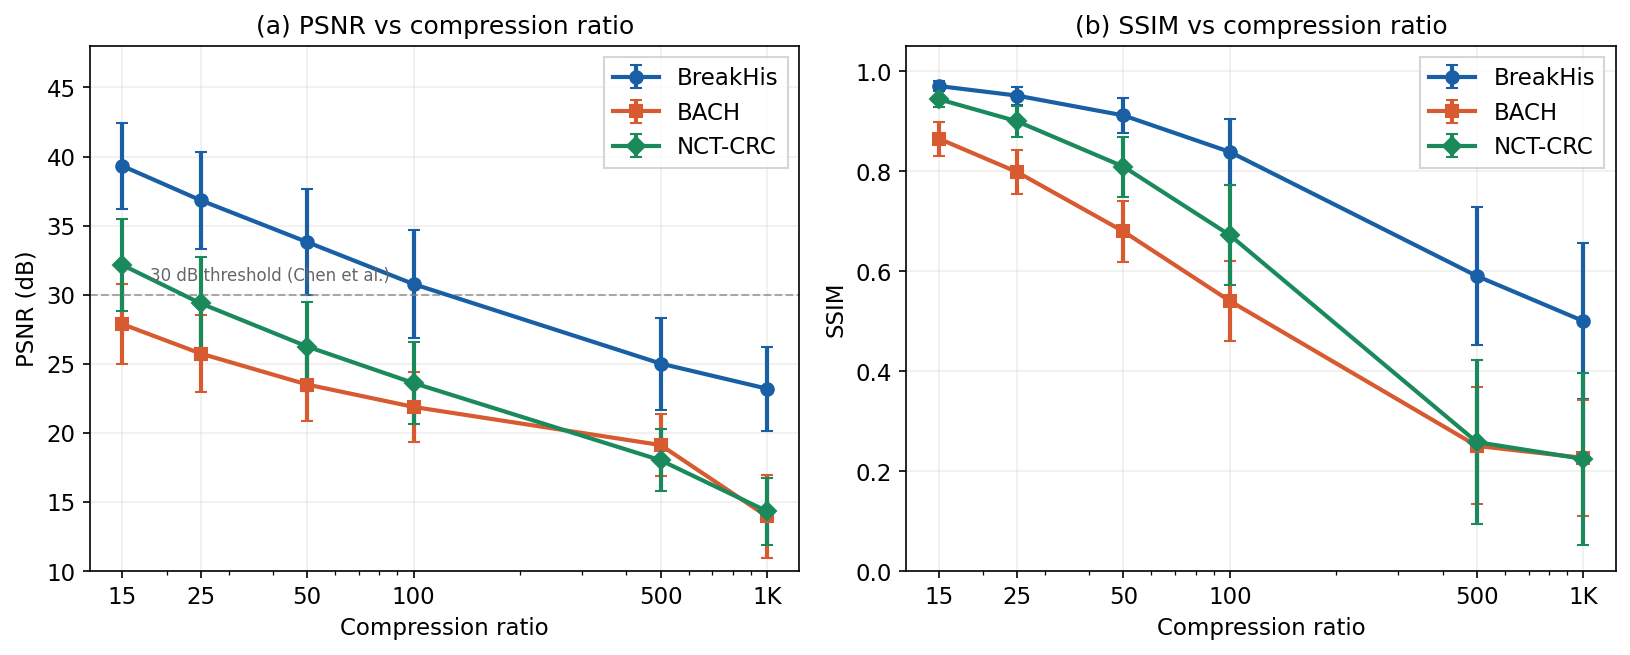

✅ fig_rate_distortion


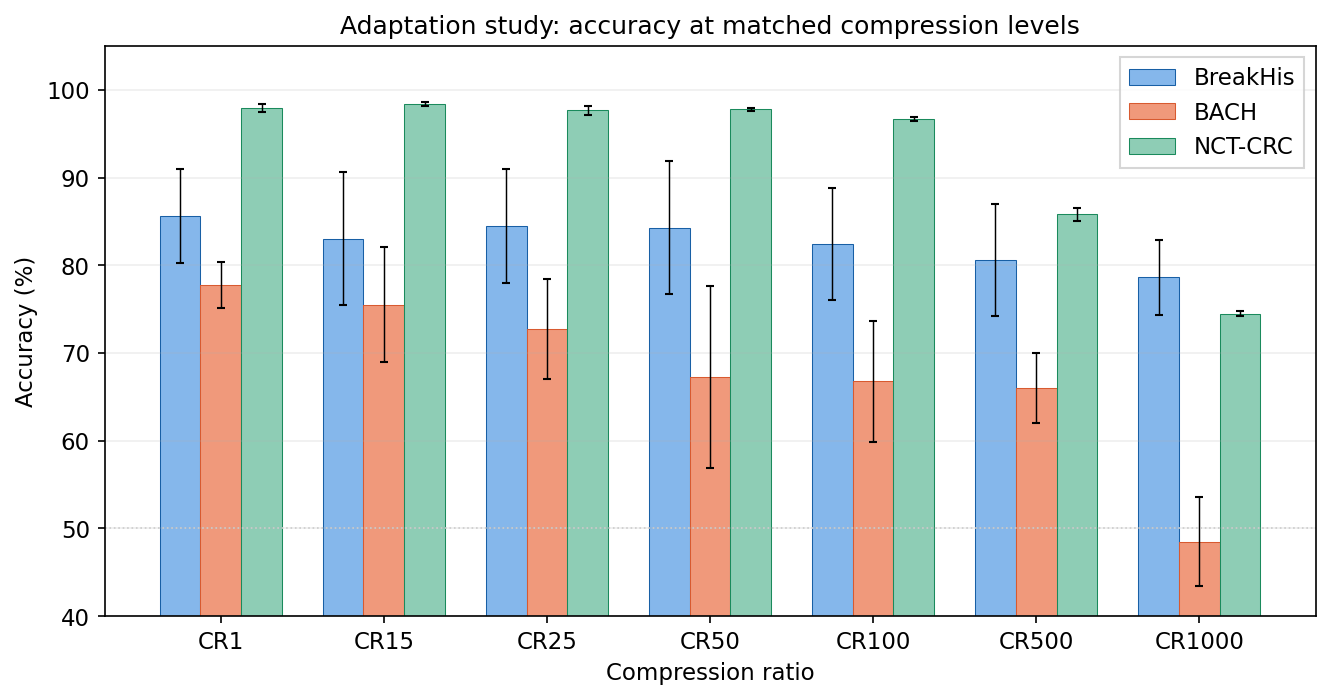

✅ fig_adaptation


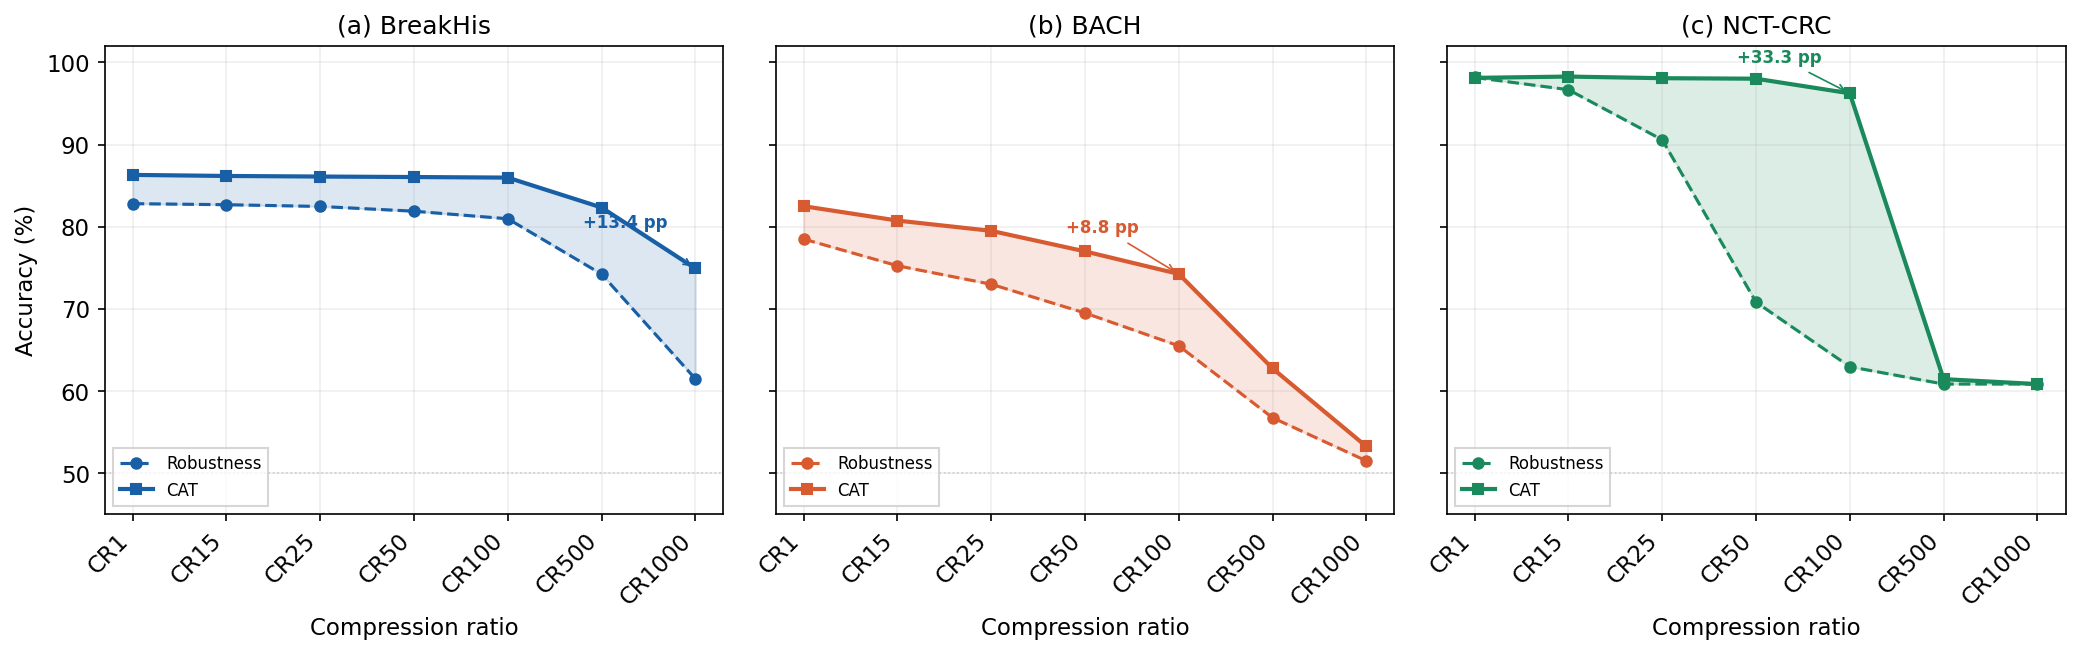

✅ fig_robustness_vs_cat


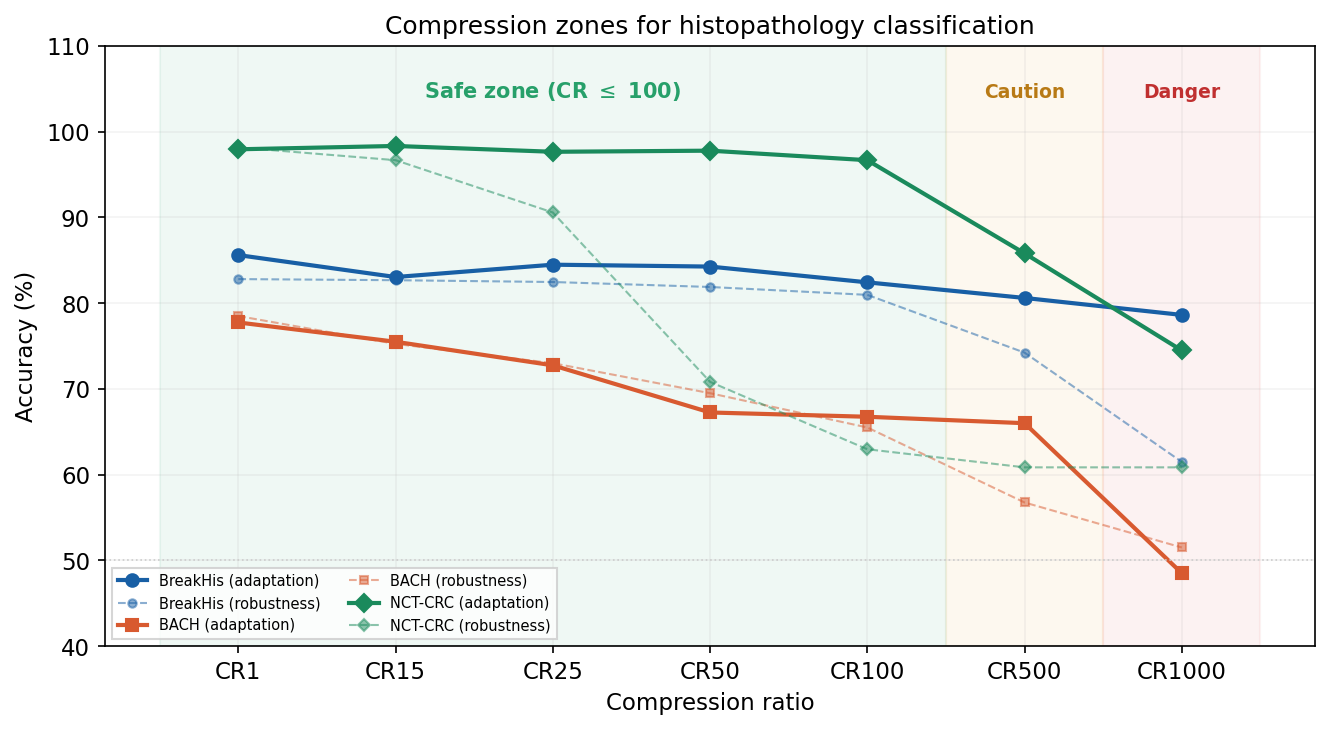

✅ fig_compression_zones


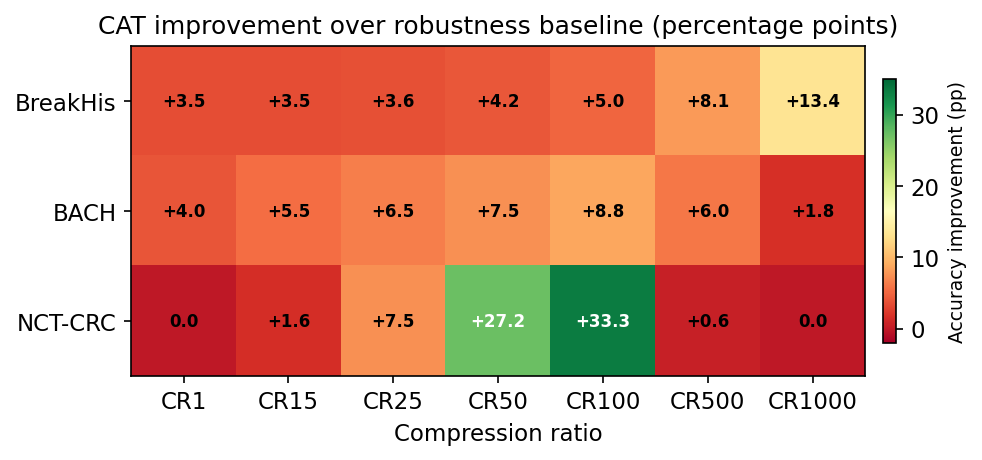

✅ fig_cat_improvement


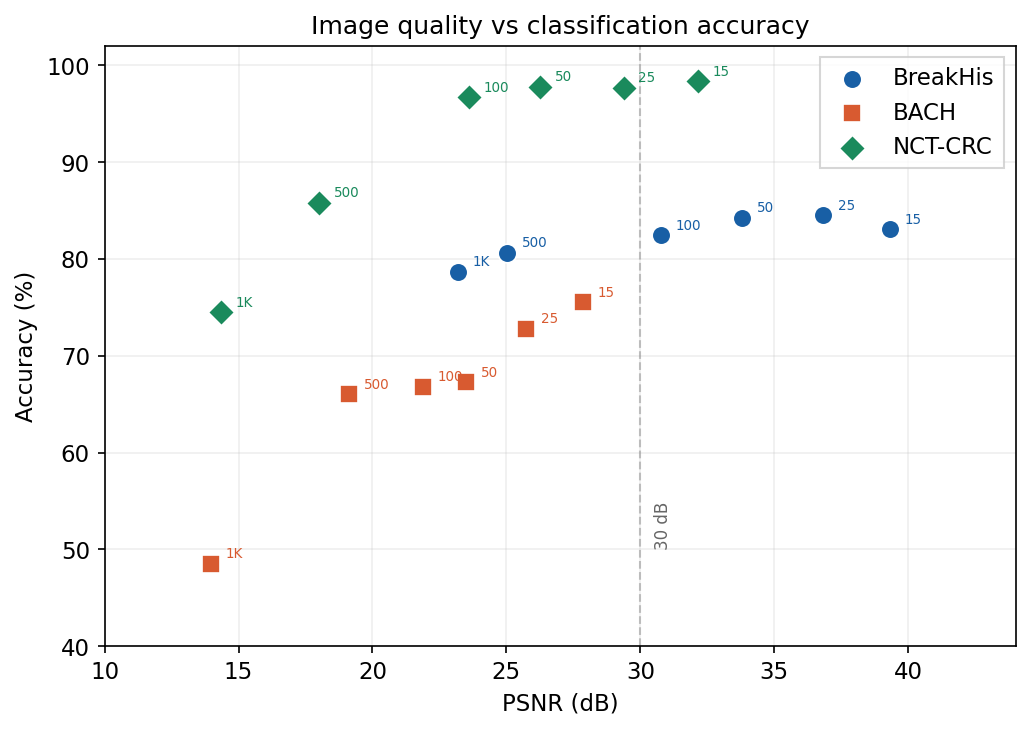

✅ fig_psnr_vs_accuracy


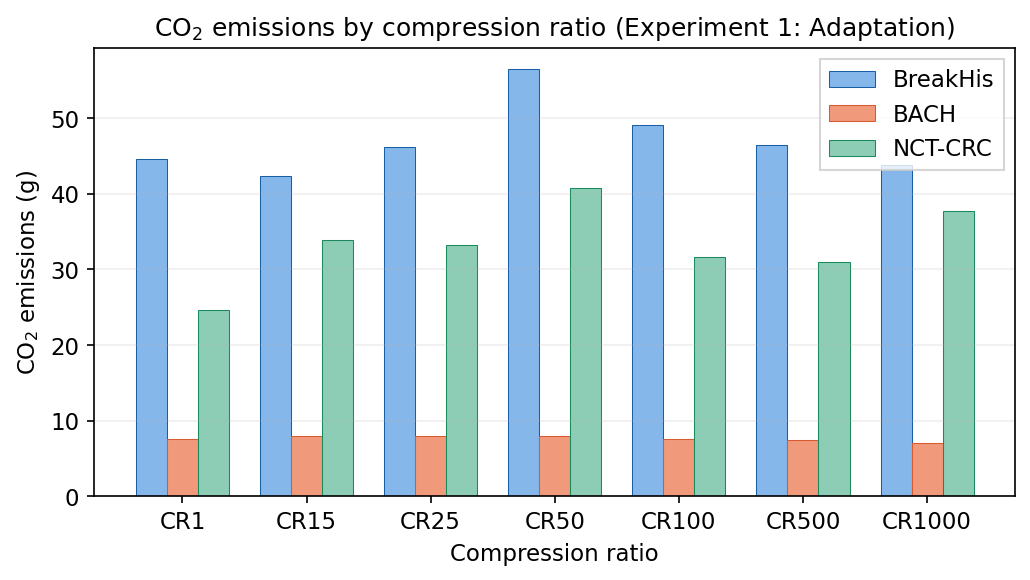

✅ fig_co2_by_cr

  All figures saved to: /content/drive/MyDrive/JPEG2000_Paper_Final/figures


In [2]:
"""
Generate all figures — FINAL with NCT-CRC balanced splits.
Run in Colab on CPU.
"""

import numpy as np
import matplotlib.pyplot as plt
import os

OUTPUT_DIR = '/content/drive/MyDrive/JPEG2000_Paper_Final/figures'
os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.rcParams.update({
    'font.size': 11, 'font.family': 'sans-serif',
    'axes.titlesize': 12, 'axes.labelsize': 11,
    'figure.dpi': 150, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
})

CR_LABELS = ['CR1','CR15','CR25','CR50','CR100','CR500','CR1000']
cr_x = [15, 25, 50, 100, 500, 1000]

C_BH = '#185FA5'; C_BA = '#D85A30'; C_NC = '#1A8A5C'
colors = {'BreakHis': C_BH, 'BACH': C_BA, 'NCT-CRC': C_NC}
markers = {'BreakHis': 'o', 'BACH': 's', 'NCT-CRC': 'D'}

# ── DATA (NCT-CRC UPDATED WITH BALANCED SPLITS) ──

rd = {
    'BreakHis': {'psnr': [39.32,36.83,33.81,30.77,25.02,23.20], 'psnr_sd': [3.10,3.53,3.81,3.89,3.33,3.03],
                 'ssim': [0.97,0.9508,0.9112,0.8382,0.59,0.50], 'ssim_sd': [0.0097,0.0181,0.0356,0.0657,0.1384,0.1552]},
    'BACH':     {'psnr': [27.87,25.74,23.50,21.88,19.12,13.96], 'psnr_sd': [2.87,2.78,2.66,2.55,2.25,2.99],
                 'ssim': [0.8649,0.798,0.6792,0.5401,0.2503,0.2263], 'ssim_sd': [0.0341,0.0437,0.0605,0.0809,0.1171,0.1161]},
    'NCT-CRC':  {'psnr': [32.15,29.37,26.25,23.61,18.02,14.33], 'psnr_sd': [3.34,3.33,3.21,2.96,2.23,2.42],
                 'ssim': [0.9437,0.8994,0.8088,0.6718,0.2579,0.2242], 'ssim_sd': [0.016,0.0305,0.0602,0.1001,0.1647,0.1723]},
}

adapt = {
    'BreakHis': [85.61,83.05,84.49,84.27,82.43,80.61,78.63],
    'BreakHis_sd': [5.34,7.57,6.52,7.59,6.38,6.38,4.29],
    'BACH': [77.75,75.50,72.75,67.25,66.75,66.00,48.50],
    'BACH_sd': [2.62,6.56,5.71,10.35,6.87,3.98,5.04],
    'NCT-CRC': [97.95,98.34,97.66,97.79,96.68,85.81,74.48],
    'NCT-CRC_sd': [0.43,0.22,0.52,0.19,0.21,0.73,0.28],
}

robust = {
    'BreakHis': [82.81,82.68,82.47,81.89,80.97,74.23,61.48],
    'BACH': [78.50,75.25,73.00,69.50,65.50,56.75,51.50],
    'NCT-CRC': [98.17,96.68,90.58,70.82,62.96,60.85,60.85],
}

cat = {
    'BreakHis': [86.31,86.18,86.11,86.05,85.98,82.34,74.92],
    'BACH': [82.50,80.75,79.50,77.00,74.25,62.75,53.25],
    'NCT-CRC': [98.12,98.28,98.08,98.02,96.24,61.45,60.85],
}


# ════════════════════════════════════════════
# FIG: RATE-DISTORTION
# ════════════════════════════════════════════
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for ds in ['BreakHis', 'BACH', 'NCT-CRC']:
    ax1.errorbar(cr_x, rd[ds]['psnr'], yerr=rd[ds]['psnr_sd'], marker=markers[ds],
                 markersize=6, linewidth=2, capsize=3, color=colors[ds], label=ds)
    ax2.errorbar(cr_x, rd[ds]['ssim'], yerr=rd[ds]['ssim_sd'], marker=markers[ds],
                 markersize=6, linewidth=2, capsize=3, color=colors[ds], label=ds)
ax1.axhline(y=30, color='#888', linestyle='--', linewidth=1, alpha=0.7)
ax1.text(18, 31, '30 dB threshold (Chen et al.)', fontsize=8, color='#666')
for ax, ylabel, title, ylim in [(ax1,'PSNR (dB)','(a) PSNR vs compression ratio',(10,48)),
                                  (ax2,'SSIM','(b) SSIM vs compression ratio',(0,1.05))]:
    ax.set_xscale('log'); ax.set_xlabel('Compression ratio'); ax.set_ylabel(ylabel)
    ax.set_title(title); ax.set_xticks(cr_x); ax.set_xticklabels(['15','25','50','100','500','1K'])
    ax.legend(frameon=True, fancybox=False, edgecolor='#ccc'); ax.grid(True, alpha=0.2); ax.set_ylim(ylim)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'fig_rate_distortion.pdf')); plt.savefig(os.path.join(OUTPUT_DIR, 'fig_rate_distortion.png'))
plt.show(); print("✅ fig_rate_distortion")


# ════════════════════════════════════════════
# FIG: ADAPTATION BAR CHART
# ════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(CR_LABELS)); w = 0.25
for i, (ds, c_fill, c_edge) in enumerate([('BreakHis','#85B7EB',C_BH),('BACH','#F0997B',C_BA),('NCT-CRC','#8ECDB5',C_NC)]):
    ax.bar(x + (i-1)*w, adapt[ds], w, yerr=adapt[ds+'_sd'], label=ds,
           color=c_fill, edgecolor=c_edge, linewidth=0.5, capsize=2, error_kw={'linewidth':0.7})
ax.set_xlabel('Compression ratio'); ax.set_ylabel('Accuracy (%)')
ax.set_title('Adaptation study: accuracy at matched compression levels')
ax.set_xticks(x); ax.set_xticklabels(CR_LABELS)
ax.legend(frameon=True, fancybox=False, edgecolor='#ccc'); ax.set_ylim(40, 105); ax.grid(True, axis='y', alpha=0.2)
ax.axhline(y=50, color='#ccc', linestyle=':', linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'fig_adaptation.pdf')); plt.savefig(os.path.join(OUTPUT_DIR, 'fig_adaptation.png'))
plt.show(); print("✅ fig_adaptation")


# ════════════════════════════════════════════
# FIG: ROBUSTNESS vs CAT (3 panels)
# ════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
x = np.arange(len(CR_LABELS))
for ax, ds, title in zip(axes, ['BreakHis','BACH','NCT-CRC'], ['(a) BreakHis','(b) BACH','(c) NCT-CRC']):
    c = colors[ds]
    ax.plot(x, robust[ds], 'o--', color=c, linewidth=1.5, markersize=5, label='Robustness')
    ax.plot(x, cat[ds], 's-', color=c, linewidth=2, markersize=5, label='CAT')
    ax.fill_between(x, robust[ds], cat[ds], alpha=0.15, color=c)
    ax.axhline(y=50, color='#ccc', linestyle=':', linewidth=0.8)
    ax.set_xlabel('Compression ratio'); ax.set_title(title)
    ax.set_xticks(x); ax.set_xticklabels(CR_LABELS, rotation=45, ha='right')
    ax.legend(frameon=True, fancybox=False, edgecolor='#ccc', loc='lower left', fontsize=8)
    ax.grid(True, alpha=0.2); ax.set_ylim(45, 102)
    deltas = [cat[ds][i] - robust[ds][i] for i in range(len(CR_LABELS))]
    max_idx = np.argmax(deltas)
    if deltas[max_idx] > 1:
        ax.annotate(f'+{deltas[max_idx]:.1f} pp', xy=(max_idx, cat[ds][max_idx]),
                    xytext=(max(0, max_idx-1.2), min(cat[ds][max_idx]+5, 100)),
                    fontsize=8, fontweight='bold', color=c,
                    arrowprops=dict(arrowstyle='->', color=c, lw=0.8))
axes[0].set_ylabel('Accuracy (%)')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'fig_robustness_vs_cat.pdf')); plt.savefig(os.path.join(OUTPUT_DIR, 'fig_robustness_vs_cat.png'))
plt.show(); print("✅ fig_robustness_vs_cat")


# ════════════════════════════════════════════
# FIG: COMPRESSION ZONES
# ════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(CR_LABELS))
for ds in ['BreakHis', 'BACH', 'NCT-CRC']:
    ax.plot(x, adapt[ds], '-', marker=markers[ds], color=colors[ds], linewidth=2, markersize=6, label=f'{ds} (adaptation)')
    ax.plot(x, robust[ds], '--', marker=markers[ds], color=colors[ds], linewidth=1, markersize=4, alpha=0.5, label=f'{ds} (robustness)')
ax.axvspan(-0.5, 4.5, alpha=0.07, color='#27A06A', zorder=0)
ax.axvspan(4.5, 5.5, alpha=0.07, color='#EF9F27', zorder=0)
ax.axvspan(5.5, 6.5, alpha=0.07, color='#E24B4A', zorder=0)
ax.text(2, 104, 'Safe zone (CR $\\leq$ 100)', fontsize=10, fontweight='bold', color='#27A06A', ha='center')
ax.text(5, 104, 'Caution', fontsize=9, fontweight='bold', color='#B87A15', ha='center')
ax.text(6, 104, 'Danger', fontsize=9, fontweight='bold', color='#C03030', ha='center')
ax.axhline(y=50, color='#ccc', linestyle=':', linewidth=0.8)
ax.set_xlabel('Compression ratio'); ax.set_ylabel('Accuracy (%)')
ax.set_title('Compression zones for histopathology classification')
ax.set_xticks(x); ax.set_xticklabels(CR_LABELS)
ax.legend(frameon=True, fancybox=False, edgecolor='#ccc', loc='lower left', fontsize=7, ncol=2)
ax.grid(True, alpha=0.15); ax.set_ylim(40, 110)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'fig_compression_zones.pdf')); plt.savefig(os.path.join(OUTPUT_DIR, 'fig_compression_zones.png'))
plt.show(); print("✅ fig_compression_zones")


# ════════════════════════════════════════════
# FIG: CAT IMPROVEMENT HEATMAP
# ════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(7, 3.2))
delta = np.array([
    [c - r for c, r in zip(cat['BreakHis'], robust['BreakHis'])],
    [c - r for c, r in zip(cat['BACH'], robust['BACH'])],
    [c - r for c, r in zip(cat['NCT-CRC'], robust['NCT-CRC'])],
])
im = ax.imshow(delta, cmap='RdYlGn', aspect='auto', vmin=-2, vmax=35)
ax.set_xticks(range(7)); ax.set_xticklabels(CR_LABELS)
ax.set_yticks([0,1,2]); ax.set_yticklabels(['BreakHis', 'BACH', 'NCT-CRC'])
ax.set_xlabel('Compression ratio')
ax.set_title('CAT improvement over robustness baseline (percentage points)')
for i in range(3):
    for j in range(7):
        v = delta[i, j]
        color = 'white' if abs(v) > 15 else 'black'
        text = f'+{v:.1f}' if v > 0 else (f'{v:.1f}' if v < -0.1 else '0.0')
        ax.text(j, i, text, ha='center', va='center', fontsize=8, fontweight='bold', color=color)
plt.colorbar(im, ax=ax, shrink=0.8, pad=0.02).set_label('Accuracy improvement (pp)', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'fig_cat_improvement.pdf')); plt.savefig(os.path.join(OUTPUT_DIR, 'fig_cat_improvement.png'))
plt.show(); print("✅ fig_cat_improvement")


# ════════════════════════════════════════════
# FIG: PSNR vs ACCURACY SCATTER
# ════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(7, 5))
for ds in ['BreakHis', 'BACH', 'NCT-CRC']:
    ax.scatter(rd[ds]['psnr'], adapt[ds][1:], s=80, marker=markers[ds],
               color=colors[ds], edgecolors='white', linewidth=0.8, label=ds, zorder=3)
    for i, cr in enumerate(['15','25','50','100','500','1K']):
        ax.annotate(cr, (rd[ds]['psnr'][i], adapt[ds][i+1]),
                    textcoords='offset points', xytext=(7, 3), fontsize=6.5, color=colors[ds])
ax.axvline(x=30, color='#888', linestyle='--', linewidth=1, alpha=0.5)
ax.text(30.5, 50, '30 dB', fontsize=8, color='#666', rotation=90, va='bottom')
ax.set_xlabel('PSNR (dB)'); ax.set_ylabel('Accuracy (%)')
ax.set_title('Image quality vs classification accuracy')
ax.legend(frameon=True, fancybox=False, edgecolor='#ccc')
ax.grid(True, alpha=0.2); ax.set_ylim(40, 102); ax.set_xlim(10, 44)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'fig_psnr_vs_accuracy.pdf')); plt.savefig(os.path.join(OUTPUT_DIR, 'fig_psnr_vs_accuracy.png'))
plt.show(); print("✅ fig_psnr_vs_accuracy")


# ════════════════════════════════════════════
# FIG: CO2 PER CR (NCT-CRC)
# ════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(7, 4))
cr_labels_co2 = ['CR1','CR15','CR25','CR50','CR100','CR500','CR1000']
co2_nct = [24.66, 33.85, 33.22, 40.78, 31.71, 31.05, 37.69]
co2_bh = [44.6, 42.4, 46.2, 56.5, 49.1, 46.5, 43.8]
co2_bach = [7.6, 8.0, 8.0, 8.0, 7.6, 7.4, 7.0]

x = np.arange(7); w = 0.25
ax.bar(x - w, co2_bh, w, color='#85B7EB', edgecolor=C_BH, linewidth=0.5, label='BreakHis')
ax.bar(x, co2_bach, w, color='#F0997B', edgecolor=C_BA, linewidth=0.5, label='BACH')
ax.bar(x + w, co2_nct, w, color='#8ECDB5', edgecolor=C_NC, linewidth=0.5, label='NCT-CRC')
ax.set_xlabel('Compression ratio'); ax.set_ylabel('CO$_2$ emissions (g)')
ax.set_title('CO$_2$ emissions by compression ratio (Experiment 1: Adaptation)')
ax.set_xticks(x); ax.set_xticklabels(cr_labels_co2)
ax.legend(frameon=True, fancybox=False, edgecolor='#ccc')
ax.grid(True, axis='y', alpha=0.2)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'fig_co2_by_cr.pdf')); plt.savefig(os.path.join(OUTPUT_DIR, 'fig_co2_by_cr.png'))
plt.show(); print("✅ fig_co2_by_cr")


print(f"\n{'='*50}")
print(f"  All figures saved to: {OUTPUT_DIR}")
print(f"{'='*50}")